# Pet segmentation with a new backbone and decoder (MobileNetV4 + PP-LiteSeg)

This notebook re-does the `segmentation_deeplab-v3-plus_oxford-iiit.ipynb`
use case — 3-class Oxford-IIIT Pets segmentation (pet / border / background)
via `SegmentationAlbumentationsDataLoader` + `TrainingDriver` — with two more
of the new components added to this plan: the **MobileNetV4-Conv-S**
backbone (§2.2, in place of the original's `EfficientNetLiteB0`) and the
**PP-LiteSeg with UAFM** decoder (§3.2, in place of the original's
`deeplab_v3_plus`). Same dataset (the
[Oxford-IIIT Pets dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/),
Parkhi et al. 2012, already downloaded and extracted into `oxford_iiit/`),
same augmentation recipe, same `label_shift=1` trimap remap, same
`SegmentationAlbumentationsDataLoader`/`TrainingDriver` pipeline as
`segmentation_mobileone_lr-aspp_oxford-iiit.ipynb`.

**Real training, real data** — not a synthetic demo, and not the same
backbone+decoder pairing as either of this plan's other two segmentation
notebooks (`segmentation_mobileone_lr-aspp_oxford-iiit.ipynb` uses
MobileOne+LR-ASPP; `repvit_pp-liteseg_water-segmentation.ipynb` uses
RepViT+PP-LiteSeg on synthetic data). DDRNet (§3.3), the third new decoder,
is deliberately *not* used here — it's a complete, self-contained
dual-resolution network with no `backbone=` parameter at all (see its own
module docstring), so it structurally cannot be paired with MobileNetV4 or
any other backbone.

The backbone loads real ImageNet-pretrained weights (`plan.md` §12.5) and
stays **frozen for the entire run** (`unfreezed_epochs=0`) — only the
PP-LiteSeg decoder trains. Trained at 256x256 with the same recipe tuned
for `segmentation_mobileone_lr-aspp_oxford-iiit.ipynb`'s frozen-backbone,
from-scratch-decoder regime after its first pass (at the original recipe's
192x192/20-epoch/`1e-4`-LR settings) produced visibly worse boundary
predictions than the fine-tuned DeepLabv3+ baseline: 256x256 resolution,
`1e-3` learning rate (AdaBelief's own default — no pretrained features are
being fine-tuned here, so there's nothing to protect with a small LR), 80
epochs with `ReduceLROnPlateau` (cheap since a frozen backbone skips its own
backward pass), no label smoothing, and a Tversky `delta=0.7` biased toward
recall (that first pass under-predicted the thin border class rather than
over-predicting it). See the inline comments on the loss/optimizer/
`TrainingDriver` cell below for the full reasoning on each choice.


## Imports

`swiss_army_keras` must be imported *before* `tensorflow` - see
`repvit_pp-liteseg_water-segmentation.ipynb` for why (`TF_USE_LEGACY_KERAS`
QAT caveat).


In [2]:
import swiss_army_keras  # noqa: F401 - import before tensorflow
import pathlib
import tensorflow as tf

tf.random.set_seed(0)

from swiss_army_keras.dataset_utils import SegmentationAlbumentationsDataLoader
from swiss_army_keras.models import pp_liteseg
from swiss_army_keras.optimizers import AdaBeliefOptimizer
from swiss_army_keras.training_utils import TrainingDriver
from swiss_army_keras import losses, metrics
import albumentations as albu

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


I0000 00:00:1790065628.640502 3643984 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790065628.675194 3643984 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790065629.432083 3643984 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/matteo/Documents/work/SAK/swiss-army-keras/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: Tqdm

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


/home/matteo/Documents/work/SAK/swiss-army-keras/.venv/lib/python3.12/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version
/home/matteo/Documents/work/SAK/swiss-army-keras/swiss_army_keras/_backbone_zoo.py:70: UserWarning: 
----------------------------------------
Could not import `efficientnet_lite` (from the `efficientnet-lite-keras` package) - EfficientNetLiteB0-B4 backbones will not be available. Every other backbone is unaffected.
----------------------------------------
  warnings.warn(
W0000 00:00:1790065631.767949 3643984 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or 

## Dataset

The Oxford-IIIT Pets dataset (images + pixel-wise trimaps: 1=pet,
2=background, 3=border) has already been downloaded and extracted into
`oxford_iiit/images/` and `oxford_iiit/annotations/trimaps/` alongside this
notebook (shared with `segmentation_mobileone_lr-aspp_oxford-iiit.ipynb`).


In [3]:
dataset_path = "/home/matteo/Documents/work/SAK/swiss-army-keras/docs/source/notebooks/oxford_iiit/"
assert (pathlib.Path(dataset_path) / "images").exists()
assert (pathlib.Path(dataset_path) / "annotations" / "trimaps").exists()

# The Pets images.tar.gz bundles a handful of stray .mat (MATLAB) annotation
# files alongside the .jpg images in images/ - delete them, since the data
# loader lists every file in images_dir and tf.image.decode_jpeg fails on a
# non-image file with `Unknown image file format`.
mat_files = list((pathlib.Path(dataset_path) / "images").glob("*.mat"))
for f in mat_files:
    f.unlink()
if mat_files:
    print(f"removed {len(mat_files)} stray .mat file(s) from images/")

print(dataset_path)


/home/matteo/Documents/work/SAK/swiss-army-keras/docs/source/notebooks/oxford_iiit/


## Model: MobileNetV4-Conv-S backbone + PP-LiteSeg decoder

MobileNetV4 (§2.2) has a genuine single-stride-2 stem (a full 5-tap feature
pyramid, stride 2/4/8/16/32), so `pp_liteseg`'s default `feature_levels=(3,
4, 5)` applies directly - no override needed, unlike the RepViT case in
`repvit_pp-liteseg_water-segmentation.ipynb` (RepViT's 4-tap patchify stem
needs `feature_levels=(2, 3, 4)` instead).

The backbone loads real ImageNet-pretrained weights (ported from `timm`,
`plan.md` §12.5 — pass the `.weights.h5` path produced by
`scripts/port_mobilenetv4_weights.py` as `weights=`) and stays frozen
(`freeze_backbone=True`) for the whole training run below: only the
PP-LiteSeg decoder trains.

Unlike `lr_aspp`, `pp_liteseg` already returns a complete, directly-usable
`tf.keras.Model` (built straight from `input_tensor`, QAT-annotated
internally) with its `.preprocessing` attribute already set — no need to
call the returned value again on `input_tensor` or copy `.preprocessing`
by hand.

**Important**: like every decoder in this library, `pp_liteseg`'s output is
raw logits, not softmax-activated probabilities. `loss_adapter(...,
from_logits=True)` below handles this - no separate `Activation("softmax")`
wrapping needed for the `TrainingDriver`/`SegmentationAlbumentationsDataLoader`
pipeline (unlike `repvit_pp-liteseg_water-segmentation.ipynb`'s plain
`model.fit()` on raw numpy arrays, where the softmax was wrapped in by hand
before computing `tversky`/`lovasz_softmax`, losses that assume
probability-valued input).


In [4]:
IMG_SIZE = 256
N_LABELS = 3  # pet / border / background

input_tensor = tf.keras.layers.Input((IMG_SIZE, IMG_SIZE, 3), batch_size=1)

model = pp_liteseg(
    input_tensor,
    n_labels=N_LABELS,
    backbone="MobileNetV4-Conv-S",
    weights="/home/matteo/Documents/work/SAK/swiss-army-keras/pretrained_weights/mobilenetv4/MobileNetV4_ConvS.weights.h5",
    freeze_backbone=True,  # keep the pretrained backbone locked; only the decoder trains
    name="Pets",
)
model.summary()


W0000 00:00:1790065637.312763 3643984 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1790065637.455877 3643984 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5699 MB memory:  -> device: 0, name: NVIDIA RTX PRO 1000 Blackwell Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(1, 256, 256, 3)]           0         []                            
                                                                                                  
 MobileNetV4-Conv-S_backbon  [(1, 128, 128, 32),          1157472   ['input_1[0][0]']             
 e (Functional)               (1, 64, 64, 32),                                                    
                              (1, 32, 32, 64),                                                    
                              (1, 16, 16, 96),                                                    
                              (1, 8, 8, 128)]                                                     
                                                                                              

## Augmentation pipeline (unchanged from the other Pets notebooks)


In [5]:
def get_training_augmentation(width=IMG_SIZE, height=IMG_SIZE):
    train_transform = [
        albu.HorizontalFlip(p=0.5),
        albu.VerticalFlip(p=0.10),
        albu.Compose([
            albu.OneOf([
                albu.ISONoise(p=1),
                albu.MultiplicativeNoise(p=1),
                albu.GaussNoise(p=1),
                albu.ImageCompression(p=1),
            ], p=1),
            albu.OneOf([
                albu.CLAHE(p=1),
                albu.RandomBrightnessContrast(p=1),
                albu.Sharpen(p=1),
                albu.Emboss(p=1),
                albu.RandomGamma(p=1),
            ], p=0.5),
            albu.OneOf([
                albu.Blur(blur_limit=5, p=1),
                albu.MedianBlur(blur_limit=5, p=1),
                albu.MotionBlur(blur_limit=5, p=1),
            ], p=0.25),
            albu.OneOf([
                albu.RandomBrightnessContrast(p=1),
                albu.HueSaturationValue(p=1),
                albu.RGBShift(p=1),
            ], p=0.25),
            albu.OneOf([
                albu.GridDistortion(p=0.5),
                albu.OpticalDistortion(distort_limit=0.3, shift_limit=0.05, p=1),
            ], p=0.25),
        ], p=0.5),
        albu.ToGray(p=0.2),
    ]
    return albu.Compose(train_transform)


## Data loader

Spins up `cpu_count() // 2` worker processes producing augmented
(image, mask) pairs over ZMQ. `label_shift=1` remaps the trimap's 1-indexed
classes ({1,2,3}) to 0-indexed ({0,1,2}) before one-hot encoding.
`normalization=model.preprocessing` ensures the exact normalization
MobileNetV4 expects is applied consistently in both training and inference.


In [6]:
loader = SegmentationAlbumentationsDataLoader(
    num_classes=N_LABELS,
    batch_size=16,
    width=IMG_SIZE,
    height=IMG_SIZE,
    dataset_path=dataset_path,
    masks_dir="annotations/trimaps",
    train_augmentations=get_training_augmentation(),
    label_shift=1,
    train_val_test_split=[0.8, 0.1, 0.1],
    normalization=model.preprocessing,
)
train_set, val_set, test_set = loader.build_datasets()


/tmp/ipykernel_3643984/253672635.py:31: UserWarning: Argument(s) 'shift_limit' are not valid for transform OpticalDistortion
  albu.OpticalDistortion(distort_limit=0.3, shift_limit=0.05, p=1),


Train Images are good to go


ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable
ERROR:root:Augmentation error: 'NoneType' object is not callable


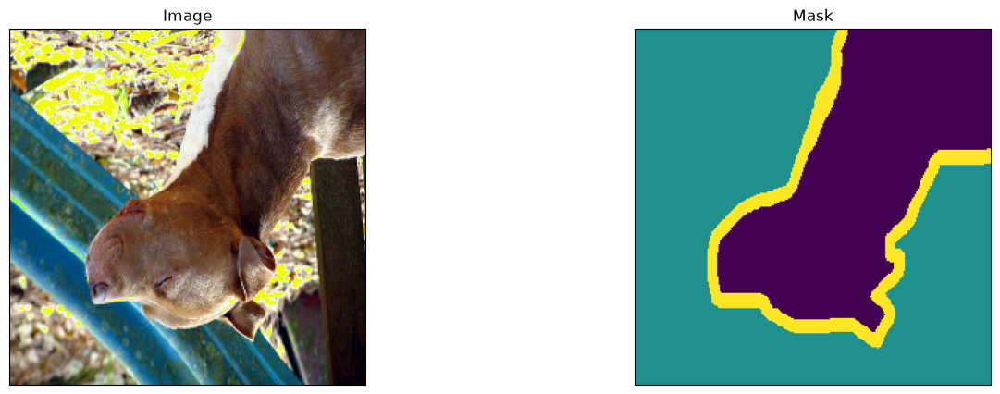

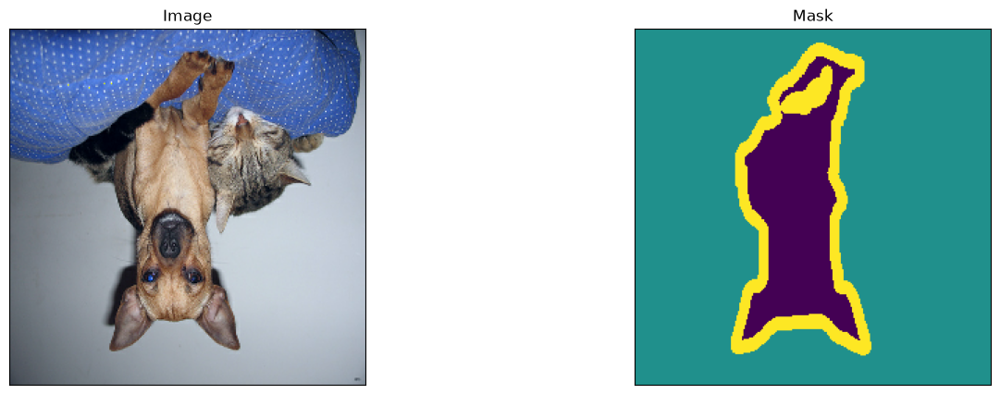

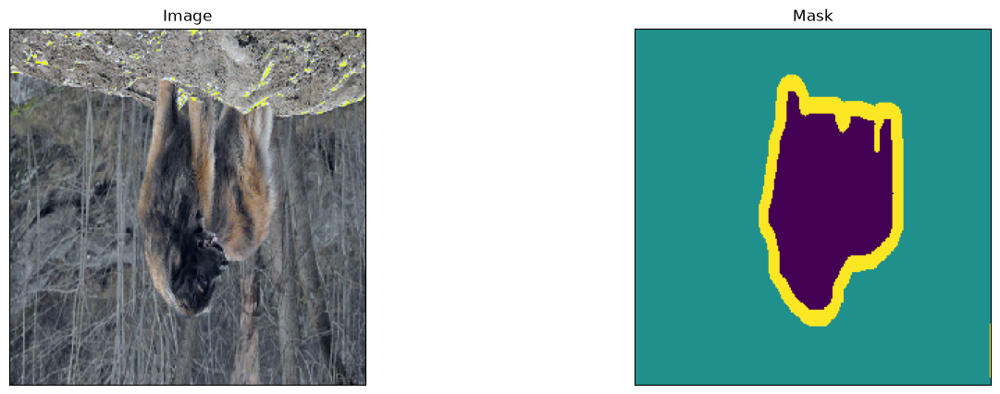

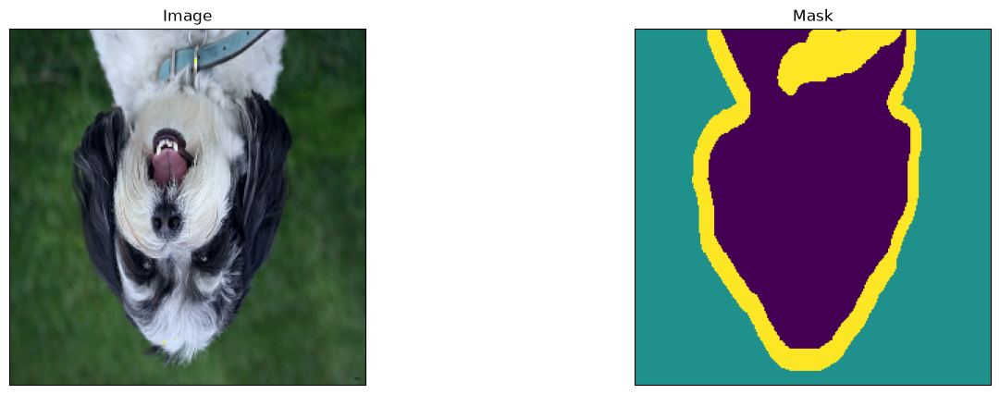

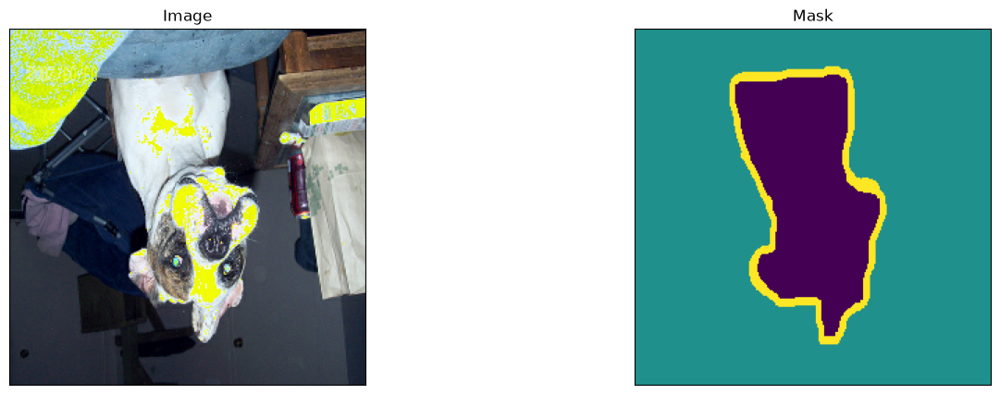

...

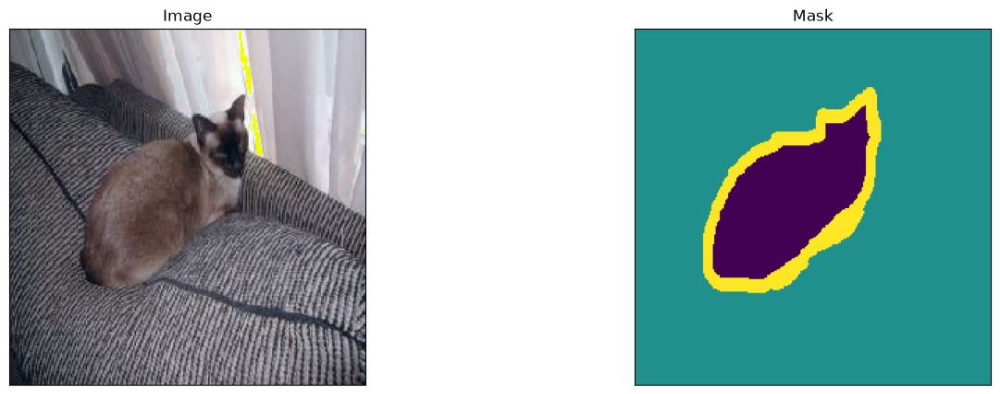

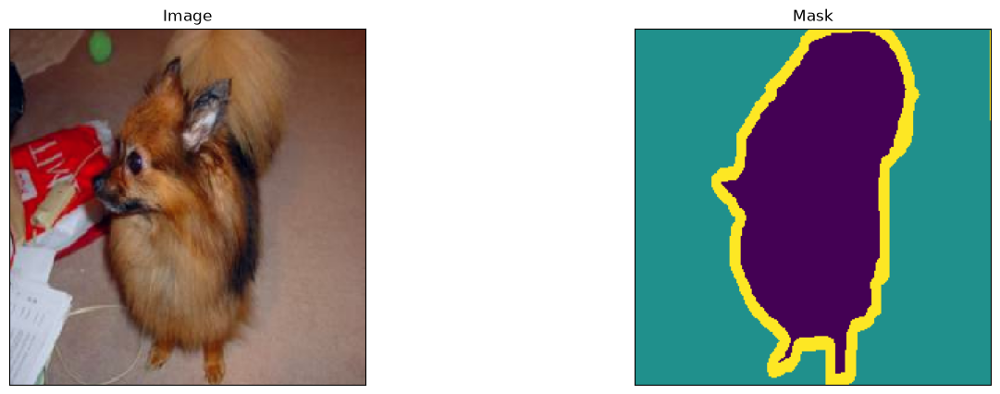

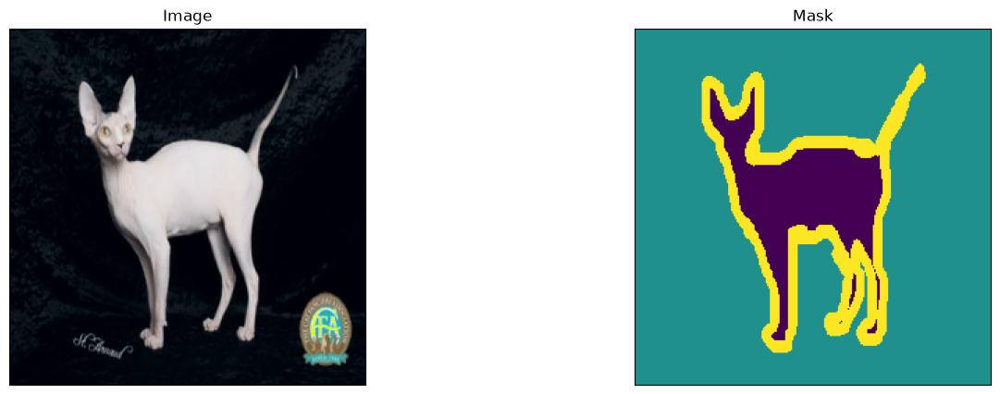

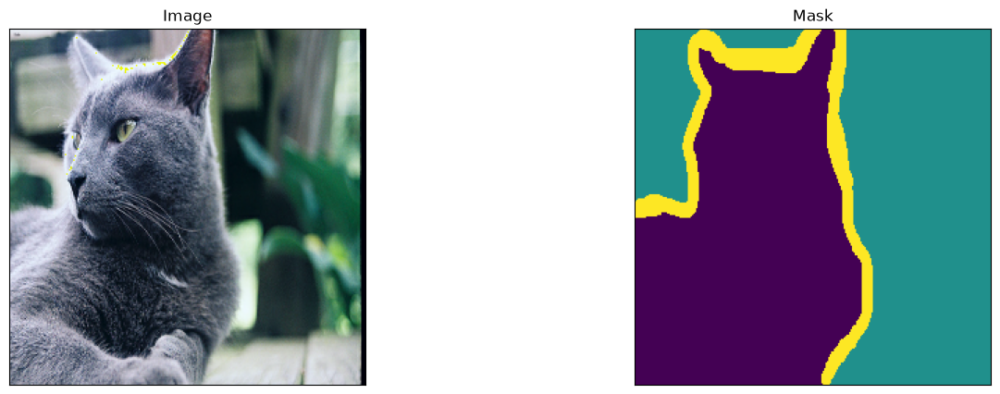

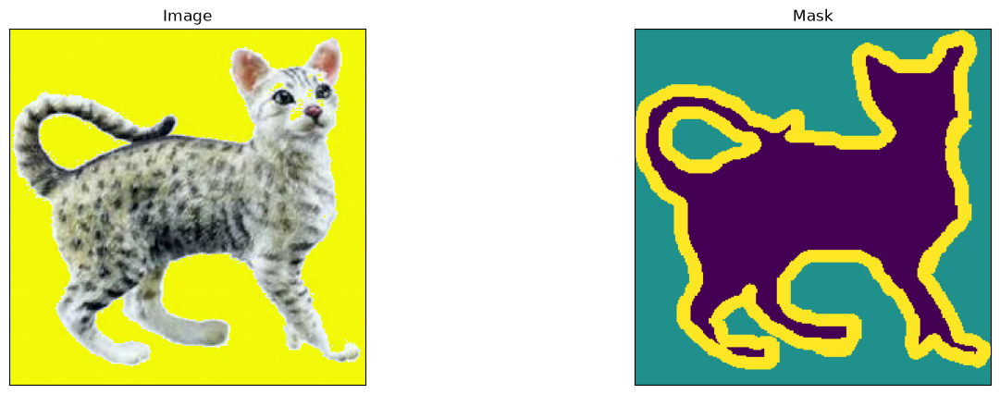

In [7]:
loader.show_images(dset="train", num_images=16)


## Train

The backbone loads real ImageNet-pretrained weights and stays frozen for
the full 80 epochs (`unfreezed_epochs=0`) — only the PP-LiteSeg decoder's
own weights are updated; the model-summary output above shows this
directly (non-trainable params dominate the total). Loss/optimizer/schedule
are tuned for a frozen-backbone, from-scratch-decoder regime, identically
to `segmentation_mobileone_lr-aspp_oxford-iiit.ipynb`'s tuned recipe — see
the inline comments in the cell below for the reasoning behind each choice.


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(1, 256, 256, 3)]           0         []                            
                                                                                                  
 MobileNetV4-Conv-S_backbon  [(1, 128, 128, 32),          1157472   ['input_1[0][0]']             
 e (Functional)               (1, 64, 64, 32),                                                    
                              (1, 32, 32, 64),                                                    
                              (1, 16, 16, 96),                                                    
                              (1, 8, 8, 128)]                                                     
                                                                                              

I0000 00:00:1790065699.377311 3644711 cuda_dnn.cc:461] Loaded cuDNN version 92600
I0000 00:00:1790065701.313868 3644707 service.cc:153] XLA service 0x73194b6ad890 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790065701.313886 3644707 service.cc:161]   StreamExecutor [0]: NVIDIA RTX PRO 1000 Blackwell Generation Laptop GPU, Compute Capability 12.0a (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1790065701.318504 3644707 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1790065701.364833 3644707 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 48/369 [==>...........................] - ETA: 19s - loss: 0.4105 - categorical_accuracy: 0.7952 - mean_iou: 0.5541

Corrupt JPEG data: premature end of data segment


300/369 [=======================>......] - ETA: 4s - loss: 0.3233 - categorical_accuracy: 0.8564 - mean_iou: 0.6517

Corrupt JPEG data: 240 extraneous bytes before marker 0xd9


... (322 outputs left out)

INFO:tensorflow:Assets written to: /tmp/tmpixug8n6f/assets


INFO:tensorflow:Assets written to: /tmp/tmpixug8n6f/assets
/home/matteo/Documents/work/SAK/swiss-army-keras/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1790067654.790614 3643984 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1790067654.790656 3643984 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1790067654.791049 3643984 reader.cc:83] Reading SavedModel from: /tmp/tmpixug8n6f
I0000 00:00:1790067654.811886 3643984 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1790067654.811955 3643984 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpixug8n6f
I0000 00:00:1790067654.943864 3643984 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1790067654.974288 3643984 loader.cc:236] Restoring SavedModel bundle.
I

INFO:tensorflow:Assets written to: /tmp/tmpc7rm_w3w/assets


INFO:tensorflow:Assets written to: /tmp/tmpc7rm_w3w/assets
/home/matteo/Documents/work/SAK/swiss-army-keras/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1790067671.333504 3643984 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1790067671.333568 3643984 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1790067671.333904 3643984 reader.cc:83] Reading SavedModel from: /tmp/tmpc7rm_w3w
I0000 00:00:1790067671.370926 3643984 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1790067671.370969 3643984 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpc7rm_w3w
I0000 00:00:1790067671.517087 3643984 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1790067671.945884 3643984 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp

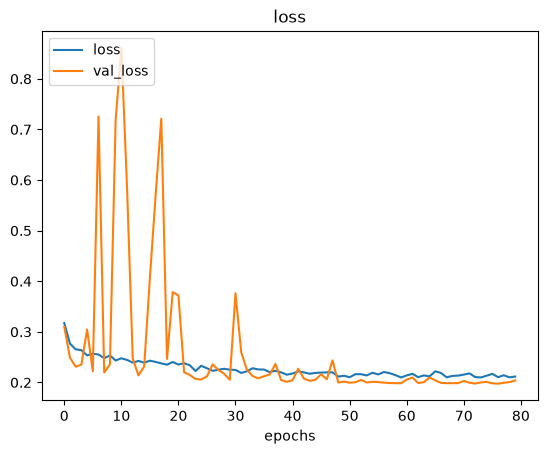

In [8]:
loss = losses.loss_adapter(
    # delta=0.7 (up from the 0.6 default): tversky_coef's alpha weights
    # false negatives more heavily as it goes up (TP / (TP + alpha*FN +
    # (1-alpha)*FP)) - the border class was consistently under-predicted
    # (missed pixels, not over-predicted ones) in the MobileOne+LR-ASPP
    # notebook's first pass, so biasing further toward recall should help
    # it here too.
    losses.symmetrical_unified_focal_loss(delta=0.7), from_logits=True,
    # label_smoothing=0.0 (down from the original recipe's 0.1): the
    # border class is already a thin minority of pixels - smoothing its
    # already-sparse one-hot target further shrinks an already weak
    # gradient signal.
    label_smoothing=0.0,
)
accuracy = tf.keras.metrics.CategoricalAccuracy()
miou = metrics.MeanIOU(num_classes=N_LABELS)

td = TrainingDriver(
    model,
    "pets_mobilenetv4_pp_liteseg",
    # learning_rate=1e-3 (AdaBelief's own default, not the original
    # recipe's fine-tuning-sized 1e-4): only a small, randomly-initialized
    # decoder trains here (see the trainable-param count in the
    # model-summary output above) - there's no pretrained backbone feature
    # to protect from a large step size.
    AdaBeliefOptimizer(learning_rate=1e-3, epsilon=1e-14),
    loss,
    [accuracy, miou],
    train_set,
    val_set,
    test_set,
    # epochs=80: a frozen backbone means no backbone backward pass, so
    # epochs are cheap - a from-scratch decoder likely needs more of them
    # to converge than a warm, already-fine-tuned backbone would.
    epochs=80,
    unfreezed_epochs=0,  # keep the pretrained backbone locked for the whole run
    # Decay the LR once validation loss plateaus, rather than holding the
    # higher 1e-3 constant for all 80 epochs - complements the built-in
    # EarlyStopping(patience=20) already wired into TrainingDriver.
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=8, min_lr=1e-6
        ),
    ],
)
td.run()


## Results


1/1 [==============================] - 1s 587ms/step


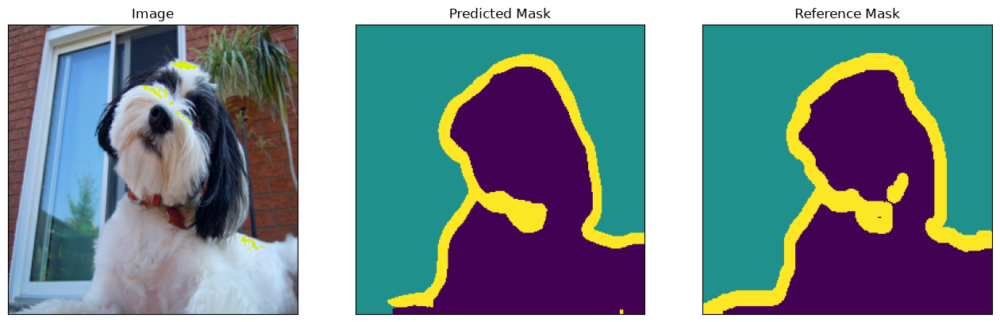

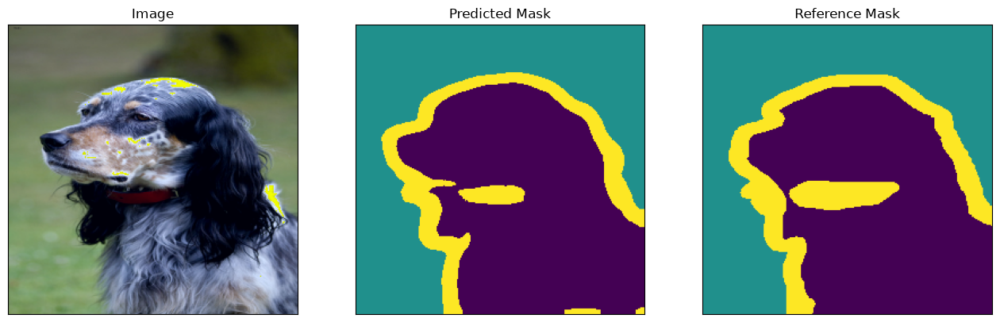

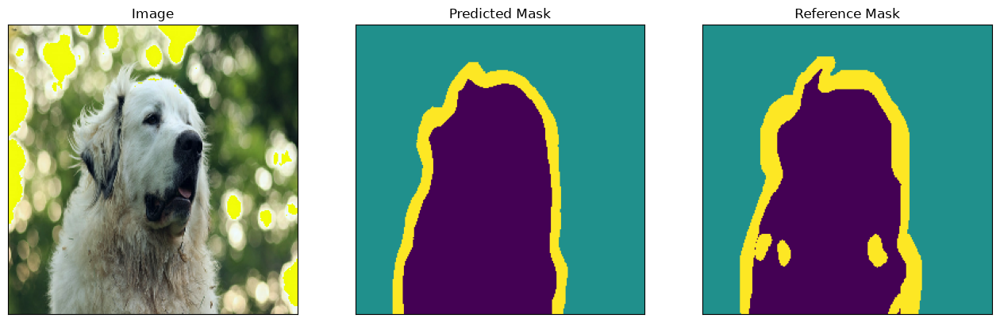

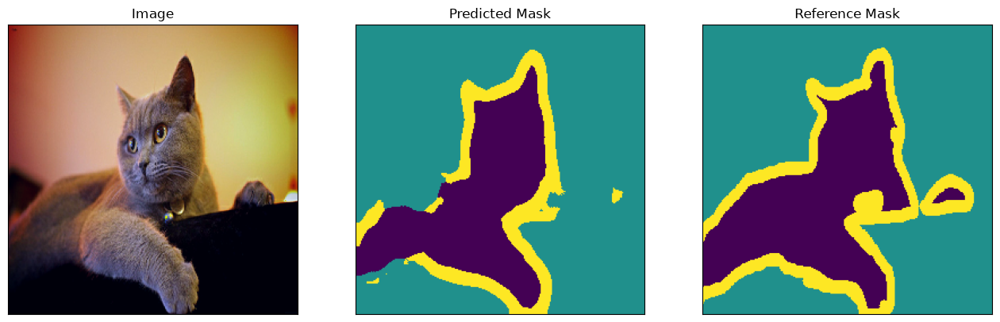

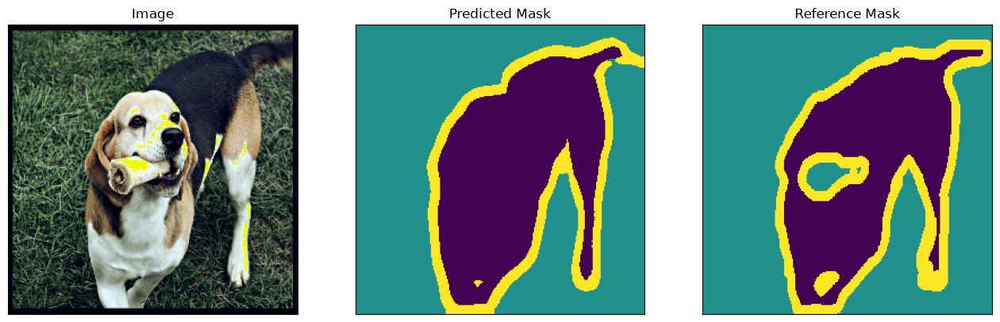

...

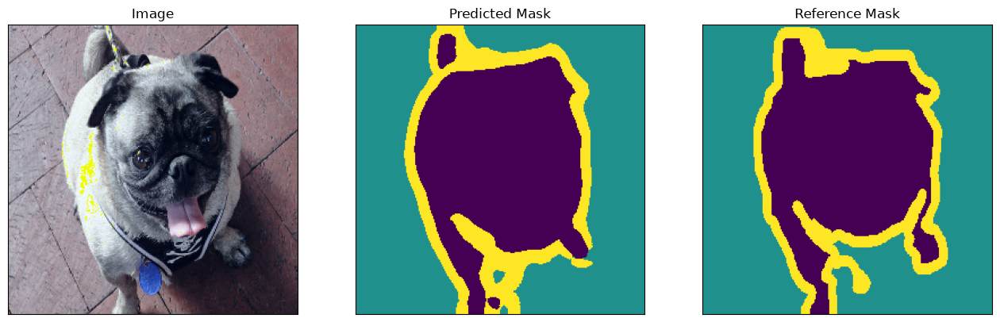

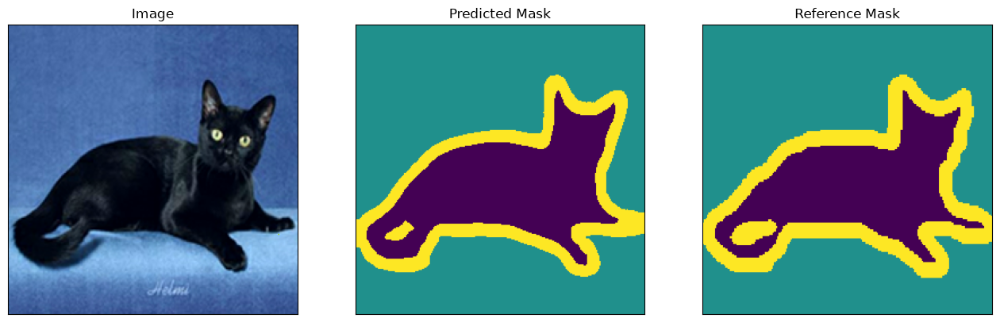

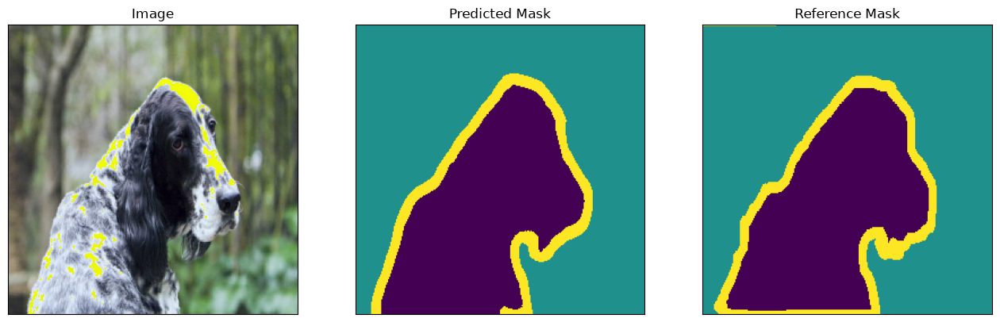

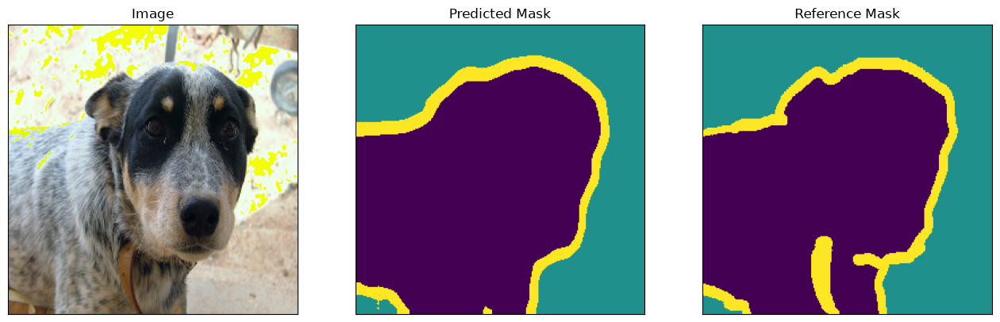

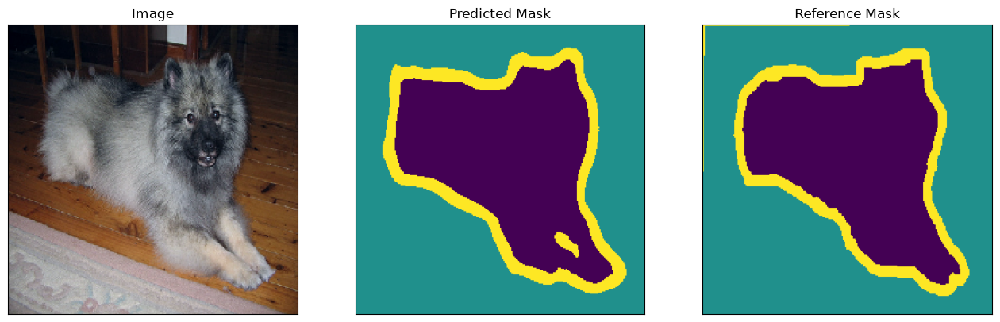

In [9]:
loader.show_results(model, 16)


## Next steps

- Try one of the other new decoders (LR-ASPP) against the same
  MobileNetV4-Conv-S backbone - only the `pp_liteseg(...)` call needs to
  change (swap for `lr_aspp(...)`, and note `lr_aspp` returns a *callable*
  sub-model rather than a complete model, so it needs the extra
  `X_decoder(input_tensor)` + `.preprocessing` copy step seen in
  `segmentation_mobileone_lr-aspp_oxford-iiit.ipynb`).
- Try a larger MobileNetV4 variant (`Conv-M`, `Conv-L`, `Hybrid-M`,
  `Hybrid-L`) - only `backbone=`/the `weights=` path need to change.
- Compare against `segmentation_mobileone_lr-aspp_oxford-iiit.ipynb`
  (MobileOne+LR-ASPP) and `segmentation_deeplab-v3-plus_oxford-iiit.ipynb`
  (the original, fine-tuned EfficientNetLiteB0+DeepLabv3+ baseline) on the
  same dataset.
